#Introduction

**Description: **This table serves as the central identity management for all Persons in the database. It contains records that uniquely identify each person or patient, and some demographic information.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
person = pd.read_csv("../data/person_202611061444.csv")

In [10]:
visit_occurrence = pd.read_csv("../data/visit_occurrence_202611061448.csv")

In [3]:
#Number of columns and rows
rows, column = (person.shape)
print(f"rows: {rows} \ncolumn {column}")

total_visit = len(person)
print(f"total_visit: {total_visit}")

rows: 912205 
column 5
total_visit: 912205


In [4]:
#Null Values
null_amount = person.isnull().sum()
null_porcent = (null_amount/total_visit)*100

summary_null = pd.DataFrame({
    'Missing values': null_amount,
    'Porcent (%)': null_porcent
})

print(summary_null.sort_values(by='Missing values', ascending=False))

                      Missing values  Porcent (%)
person_id                          0          0.0
gender_concept_id                  0          0.0
year_of_birth                      0          0.0
race_concept_id                    0          0.0
ethnicity_concept_id               0          0.0


In [5]:
#Duplicate values
list_columns = person.columns.to_list()

for i in list_columns:
    num_duplicate = person[i].duplicated().sum()

    if num_duplicate > 0:
        print(f"The column {i} has duplicate values ({num_duplicate} in total)")
    else:
        print(f"The column {i} has no duplicate")

The column person_id has no duplicate
The column gender_concept_id has duplicate values (912202 in total)
The column year_of_birth has duplicate values (912077 in total)
The column race_concept_id has duplicate values (912202 in total)
The column ethnicity_concept_id has duplicate values (912203 in total)


In [31]:
max_year = person["year_of_birth"].max()
min_year = person["year_of_birth"].min()
print(f"Latest year of birth: {max_year}\nMinimum birth year: {min_year}")

list_years = person["year_of_birth"].value_counts()
print(list_years)

invalid_years = (person["year_of_birth"] < 1900).sum()

print(f"Number of records with invalid birth years: {invalid_years}")

count = person["year_of_birth"].value_counts().get(2026,0)
print(count)

Latest year of birth: 2026
Minimum birth year: 1
year_of_birth
2000    19649
1999    19058
1997    18522
2001    18315
1998    18299
        ...  
1903        1
1898        1
1904        1
1906        1
1907        1
Name: count, Length: 128, dtype: int64
Number of records with invalid birth years: 87
829


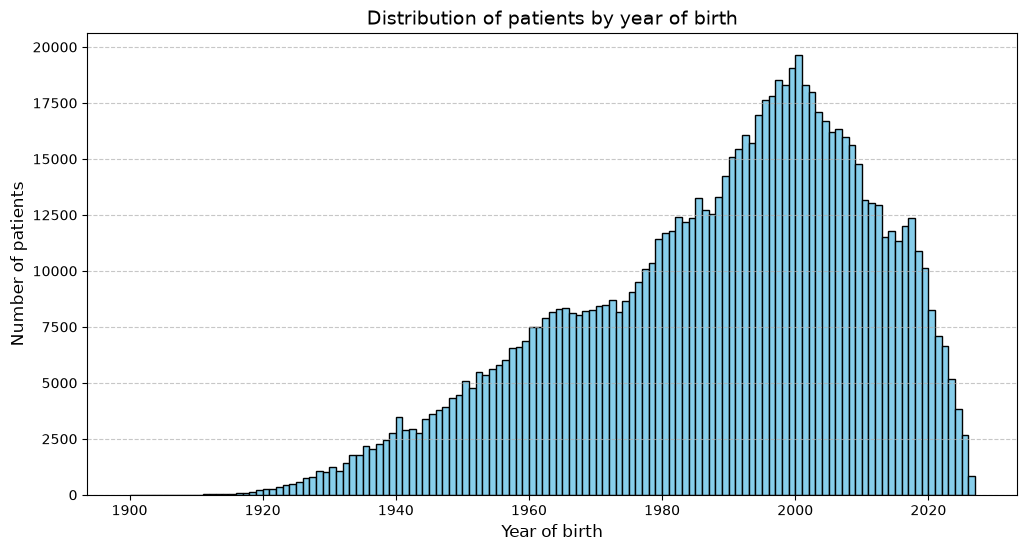

In [ ]:
#Distribution of patients by year of birth
valid_persons = person[person["year_of_birth"].between(1900, 2026)]
plt.figure(figsize=(12, 6))

plt.hist(valid_persons["year_of_birth"], bins=range(1900, 2028, 1), edgecolor='black', color='skyblue')

plt.title("Distribution of patients by year of birth", fontsize=14)
plt.xlabel("Year of birth", fontsize=12)
plt.ylabel("Number of patients", fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.show()

In [7]:
df = person["race_concept_id"].value_counts().reset_index()
df.columns = ["race_concept_id", 'frequency']
total_person = len(person)
df['percentage'] = (df['frequency'] / total_person) * 100
print(df)

   race_concept_id  frequency  percentage
0                0     867831   95.135523
1             8657      27704    3.037037
2             8516      16670    1.827440


In [9]:
df_ethnicity = person["ethnicity_concept_id"].value_counts().reset_index()
df_ethnicity.columns = ["ethnicity_concept_id", "frequency"] 
total_person = len(person)

df_ethnicity['percentage'] = (df_ethnicity['frequency'] / total_person) * 100

print(df_ethnicity)

   ethnicity_concept_id  frequency  percentage
0              38003563     910140   99.773625
1              38003564       2065    0.226375


In [ ]:
# Check patients with and without visits

patients_with_visits = person["person_id"].isin(visit_occurrence["person_id"])

# Count patients
with_visits = patients_with_visits.sum()
without_visits = (~patients_with_visits).sum()

# Calculate percentages
total_patients = len(person)

percentage_with = (with_visits / total_patients) * 100
percentage_without = (without_visits / total_patients) * 100

print(f"Total patients: {total_patients}")
print(f"Patients with visits: {with_visits} ({percentage_with:.2f}%)")
print(f"Patients without visits: {without_visits} ({percentage_without:.2f}%)")

Total patients: 912205
Patients with visits: 304457 (33.38%)
Patients without visits: 607748 (66.62%)


In [15]:
# Number of visits per patient
visits_per_patient = visit_occurrence["person_id"].value_counts()

# Distribution of visits per patient
visits_distribution = visits_per_patient.value_counts().sort_index()

print("Distribution of visits per patient:")
print(visits_distribution)

# Statistics
average_visits = visits_per_patient.mean()
median_visits = visits_per_patient.median()
max_visits = visits_per_patient.max()

print(f"\nAverage visits per patient: {average_visits:.2f}")
print(f"Median visits per patient: {median_visits:.2f}")
print(f"Maximum visits per patient: {max_visits}")

print("Patients with visits:", len(visits_per_patient))
print("Total visits counted:", visits_per_patient.sum())

# Patient with the highest number of visits
patient_with_most_visits = visits_per_patient.idxmax()

# Maximum number of visits
max_visits = visits_per_patient.max()

# Verify if the patient exists in PERSON
exists = person["person_id"].eq(patient_with_most_visits).any()

print(f"Maximum visits: {max_visits}")
print(f"Patient exists in PERSON: {exists}")

Distribution of visits per patient:
count
1       51293
2       89301
3       39354
4       31851
5       17381
        ...  
880         1
894         1
918         1
1118        1
1218        1
Name: count, Length: 291, dtype: int64

Average visits per patient: 5.60
Median visits per patient: 3.00
Maximum visits per patient: 1218
Patients with visits: 304457
Total visits counted: 1706001
Maximum visits: 1218
Patient exists in PERSON: True


In [ ]:
### PERSON – Key Findings and Conclusions

1. The `PERSON` table contains 912,205 patient records. The exploratory analysis included missing values, duplicate records, demographic distributions, and relationships with `VISIT_OCCURRENCE`.

2. The gender distribution consists of approximately 53.06% female patients, 46.92% male patients, and 0.01% with an unmapped gender concept.

3. A total of 87 records contain birth years earlier than 1900, representing approximately 0.0095% of the dataset. These values were flagged as potentially invalid and should be considered during data preprocessing.

4. The `race_concept_id` column has limited informational value, as 95.14% of patients have a value of 0, indicating an unmapped or unspecified race concept.

5. The ethnicity distribution is highly imbalanced: 99.77% of patients are classified as *Not Hispanic or Latino*, while 0.23% are classified as *Hispanic or Latino*. This distribution should be interpreted cautiously due to potential mapping or coding limitations.

6. Of the 912,205 patients, 304,457 (33.38%) have at least one recorded visit in `VISIT_OCCURRENCE`, while 607,748 (66.62%) have no associated visits in the available dataset.

7. Among patients with recorded visits, the average number of visits is 5.60 and the median is 3, indicating a right-skewed distribution.

8. The maximum number of visits associated with a single patient is 1,218. The patient's identifier was successfully verified in `PERSON`, although this unusually high visit frequency remains a potential outlier requiring further investigation.

9. Overall, `PERSON` provides useful demographic and patient recurrence information. However, data quality limitations and the availability of predictors at forecasting time must be considered before incorporating these variables into a demand prediction model.